<a href="https://colab.research.google.com/github/irfanizzath/Boston-Housing-xAI/blob/main/Explainable_AI_Boston_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable AI (XAI) — Hands-On Notebook
### Dataset: Boston Housing (regression)

This notebook implements every major Explainable AI
technique on a single, consistent dataset — the classic **Boston Housing** dataset
(506 rows, 13 features, target `medv` = median home value in $1000s).

**Covers:**
1. Foundations — linear model coefficients, decision tree rules & feature importance, random forest importance
2. Model-Agnostic — permutation importance, SHAP (Tree & Kernel explainers), SHAP visualizations (bar, beeswarm, dependence, PDP)
3. Local Explainability — SHAP waterfall/force plots, LIME for tabular regression
4. Advanced Topics — explanation consistency & faithfulness checks, unsupervised (clustering) explainability with ARI

> Note: The original `sklearn.datasets.load_boston` was removed from scikit-learn for ethical
> reasons around one feature (`B`). We load the same numeric dataset from a CSV instead, purely
> for its long history as an interpretability/regression benchmark, and keep the feature as-is
> for demonstration purposes only.


In [ ]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

import shap
import lime
import lime.lime_tabular

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
shap.initjs()
np.random.seed(42)


ModuleNotFoundError: No module named 'lime'

## 1. Load & Explore the Boston Housing Dataset

**Feature dictionary:**
| Feature | Meaning |
|---|---|
| crim | per-capita crime rate by town |
| zn | proportion of residential land zoned for large lots |
| indus | proportion of non-retail business acres per town |
| chas | Charles River dummy variable (1 if tract bounds river) |
| nox | nitric oxide concentration (pollution) |
| rm | average number of rooms per dwelling |
| age | proportion of owner-occupied units built before 1940 |
| dis | weighted distance to employment centers |
| rad | index of accessibility to radial highways |
| tax | property tax rate per $10,000 |
| ptratio | pupil-teacher ratio by town |
| b | 1000(Bk - 0.63)^2 where Bk = proportion of Black residents (legacy feature, kept for demonstration only) |
| lstat | % lower status of the population |
| medv | **target** — median home value in $1000s |


In [ ]:
df = pd.read_csv("boston.csv")
df.columns = [c.strip().lower() for c in df.columns]
df['chas'] = df['chas'].astype(int)
print(df.shape)
df.head()


In [ ]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
zn,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
indus,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
chas,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
nox,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
rm,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
age,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
dis,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
rad,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
tax,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


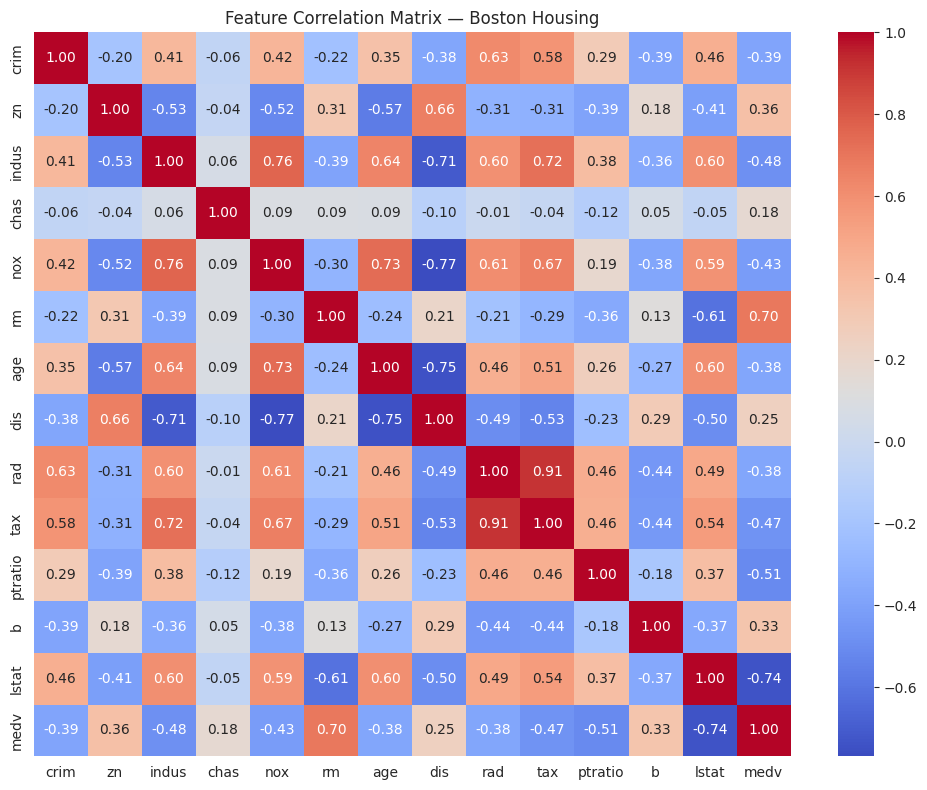

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Feature Correlation Matrix — Boston Housing")
plt.tight_layout()
plt.show()


In [ ]:
X = df.drop(columns=['medv'])
y = df['medv']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (404, 13)  Test: (102, 13)


---
## 2. Foundations of Explainable AI

### 2.1 Explainability in Linear Models — Computing Feature Impact


In [ ]:
lin_model = LinearRegression().fit(X_train_scaled, y_train)

pred = lin_model.predict(X_test_scaled)
print(f"Linear Regression  R2: {r2_score(y_test, pred):.3f}   RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f}")

coef_impact = pd.Series(lin_model.coef_, index=X.columns).sort_values(key=abs, ascending=False)
coef_impact


Linear Regression  R2: 0.669   RMSE: 4.929


lstat     -3.611658
rm         3.145240
dis       -3.081908
rad        2.251407
ptratio   -2.037752
nox       -2.022319
tax       -1.767014
b          1.129568
crim      -1.002135
chas       0.718738
zn         0.696269
indus      0.278065
age       -0.176048
dtype: float64

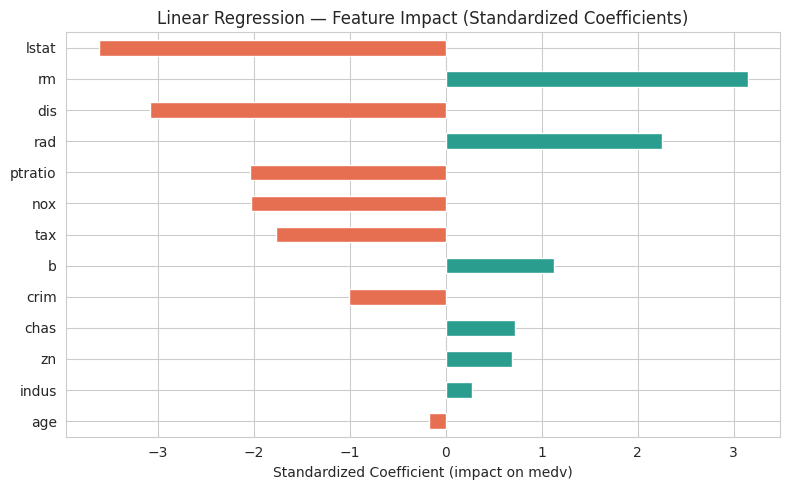

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
coef_impact.plot(kind='barh', ax=ax, color=np.where(coef_impact > 0, '#2a9d8f', '#e76f51'))
ax.set_xlabel("Standardized Coefficient (impact on medv)")
ax.set_title("Linear Regression — Feature Impact (Standardized Coefficients)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Interpretation:** Because features were standardized, coefficient magnitude is directly
comparable across features. `lstat` (% lower status population) and `rm` (rooms per dwelling)
are typically the strongest drivers of predicted home value — one pushing price down, the other up.


### 2.2 Explainability in Tree-Based Models

#### 2.2.1 Decision Tree — Extracting Rules & Feature Importance


In [ ]:
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_train, y_train)
pred_tree = tree_model.predict(X_test)
print(f"Decision Tree  R2: {r2_score(y_test, pred_tree):.3f}   RMSE: {np.sqrt(mean_squared_error(y_test, pred_tree)):.3f}")

print(export_text(tree_model, feature_names=list(X.columns), max_depth=3))


Decision Tree  R2: 0.731   RMSE: 4.444
|--- rm <= 6.94
|   |--- lstat <= 14.40
|   |   |--- dis <= 1.38
|   |   |   |--- crim <= 10.11
|   |   |   |   |--- value: [50.00]
|   |   |   |--- crim >  10.11
|   |   |   |   |--- value: [27.90]
|   |   |--- dis >  1.38
|   |   |   |--- rm <= 6.54
|   |   |   |   |--- value: [21.63]
|   |   |   |--- rm >  6.54
|   |   |   |   |--- value: [27.50]
|   |--- lstat >  14.40
|   |   |--- crim <= 6.93
|   |   |   |--- age <= 73.30
|   |   |   |   |--- value: [21.22]
|   |   |   |--- age >  73.30
|   |   |   |   |--- value: [16.43]
|   |   |--- crim >  6.93
|   |   |   |--- lstat <= 19.85
|   |   |   |   |--- value: [14.77]
|   |   |   |--- lstat >  19.85
|   |   |   |   |--- value: [10.28]
|--- rm >  6.94
|   |--- rm <= 7.44
|   |   |--- lstat <= 15.76
|   |   |   |--- dis <= 1.89
|   |   |   |   |--- value: [45.65]
|   |   |   |--- dis >  1.89
|   |   |   |   |--- value: [32.63]
|   |   |--- lstat >  15.76
|   |   |   |--- rm <= 7.18
|   |   |   |  

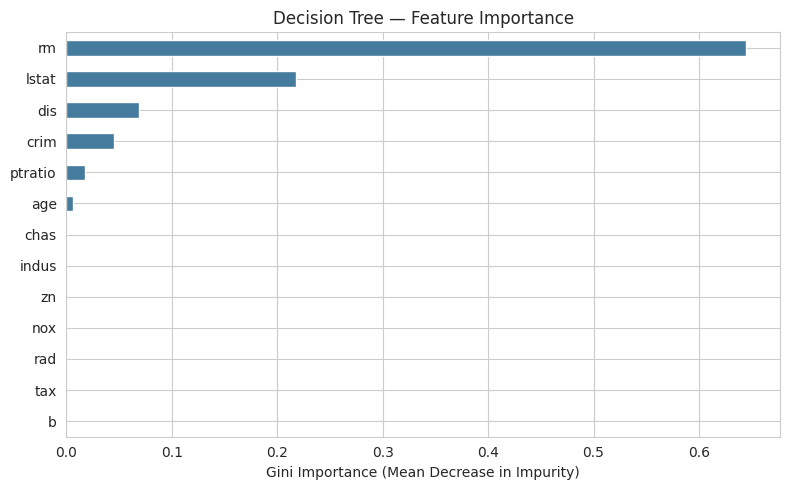

In [ ]:
tree_importance = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
tree_importance.plot(kind='barh', ax=ax, color='#457b9d')
ax.set_xlabel("Gini Importance (Mean Decrease in Impurity)")
ax.set_title("Decision Tree — Feature Importance")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


#### 2.2.2 Random Forest — Feature Importance

Random Forest  R2: 0.879   RMSE: 2.984


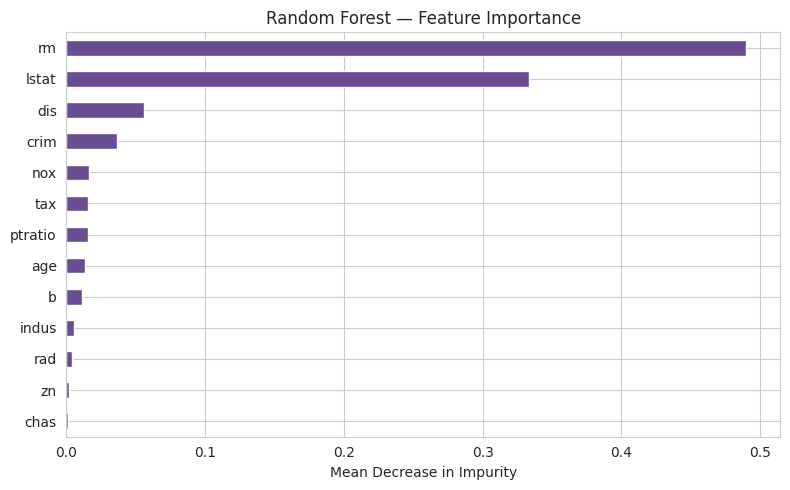

In [ ]:
rf_model = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)
print(f"Random Forest  R2: {r2_score(y_test, pred_rf):.3f}   RMSE: {np.sqrt(mean_squared_error(y_test, pred_rf)):.3f}")

rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
rf_importance.plot(kind='barh', ax=ax, color='#6a4c93')
ax.set_xlabel("Mean Decrease in Impurity")
ax.set_title("Random Forest — Feature Importance")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Model-specific vs model-agnostic:** the plots above (linear coefficients, tree/forest
`.feature_importances_`) all exploit internal model structure — they are **model-specific**.
Next we move to **model-agnostic** techniques that would work identically even if we swapped
in a neural network.


---
## 3. Model-Agnostic Explainability

### 3.1 Permutation Importance


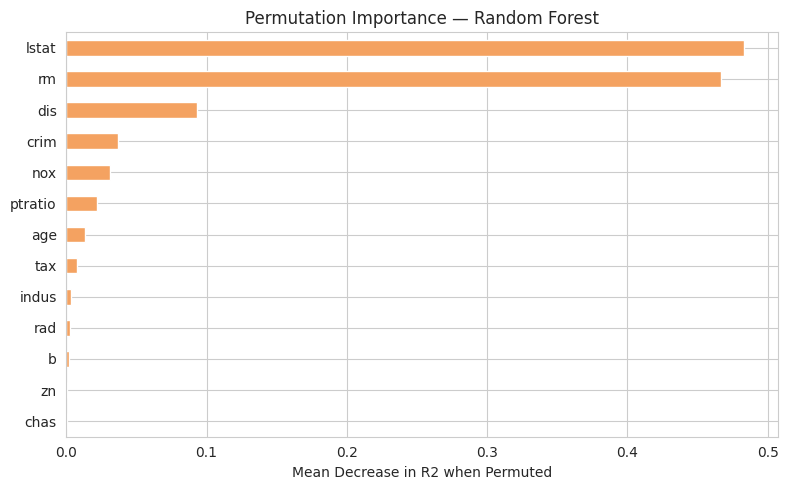

In [ ]:
perm_result_rf = permutation_importance(rf_model, X_test, y_test, n_repeats=30, random_state=42, scoring='r2')
perm_importance_rf = pd.Series(perm_result_rf.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
perm_importance_rf.plot(kind='barh', ax=ax, color='#f4a261')
ax.set_xlabel("Mean Decrease in R2 when Permuted")
ax.set_title("Permutation Importance — Random Forest")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


### 3.1.1 Permutation Importance for an MLPRegressor (neural network)

MLP Regressor  R2: 0.864   RMSE: 3.157


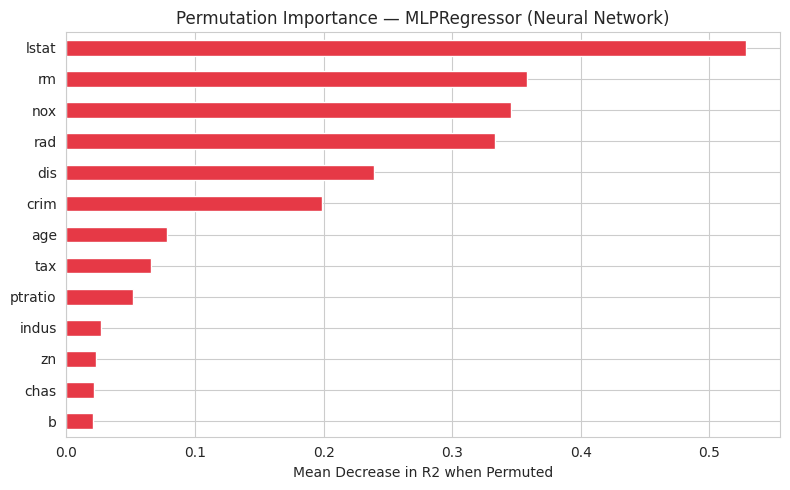

In [ ]:
mlp_model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42, early_stopping=True)
mlp_model.fit(X_train_scaled, y_train)
pred_mlp = mlp_model.predict(X_test_scaled)
print(f"MLP Regressor  R2: {r2_score(y_test, pred_mlp):.3f}   RMSE: {np.sqrt(mean_squared_error(y_test, pred_mlp)):.3f}")

perm_result_mlp = permutation_importance(mlp_model, X_test_scaled, y_test, n_repeats=30, random_state=42, scoring='r2')
perm_importance_mlp = pd.Series(perm_result_mlp.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
perm_importance_mlp.plot(kind='barh', ax=ax, color='#e63946')
ax.set_xlabel("Mean Decrease in R2 when Permuted")
ax.set_title("Permutation Importance — MLPRegressor (Neural Network)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


### 3.1.2 Coefficients vs. Permutation Importance — side-by-side comparison

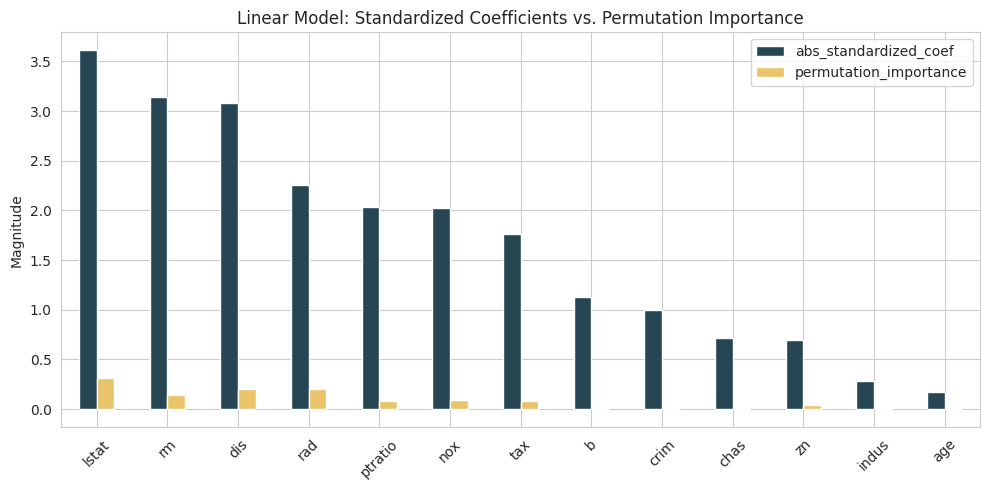

,abs_standardized_coef,permutation_importance
lstat,3.611658,0.312688
rm,3.145240,0.143423
dis,3.081908,0.205165
rad,2.251407,0.196941
ptratio,2.037752,0.085404
nox,2.022319,0.091895
tax,1.767014,0.076269
b,1.129568,-0.003913
crim,1.002135,-0.001262
chas,0.718738,0.004134


In [ ]:
perm_result_lin = permutation_importance(lin_model, X_test_scaled, y_test, n_repeats=30, random_state=42, scoring='r2')
perm_importance_lin = pd.Series(perm_result_lin.importances_mean, index=X.columns)

compare_df = pd.DataFrame({
    'abs_standardized_coef': coef_impact.abs(),
    'permutation_importance': perm_importance_lin
}).sort_values('abs_standardized_coef', ascending=False)

compare_df.plot(kind='bar', figsize=(10, 5), color=['#264653', '#e9c46a'])
plt.title("Linear Model: Standardized Coefficients vs. Permutation Importance")
plt.ylabel("Magnitude")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
compare_df


**Observation:** Rankings broadly agree but rarely match exactly — permutation importance
accounts for the model's *actual* predictive reliance on a feature (including any nonlinear
residual signal captured incidentally), while coefficients reflect the model's internal
linear weighting only.


### 3.2 SHAP Explainability

We use `shap.TreeExplainer` for our tree-based Random Forest — it is **exact and fast**
because it exploits the tree structure directly (a *model-specific* SHAP implementation).


In [ ]:
tree_explainer = shap.TreeExplainer(rf_model)
shap_values_rf = tree_explainer(X_test)

print("SHAP values shape:", shap_values_rf.values.shape)
print("Base (expected) value:", shap_values_rf.base_values[0])


SHAP values shape: (102, 13)
Base (expected) value: 22.862306930693073


#### 3.2.1 Global Feature Importance — SHAP Bar Plot

/tmp/ipykernel_571/3250947310.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test, plot_type="bar", show=False)


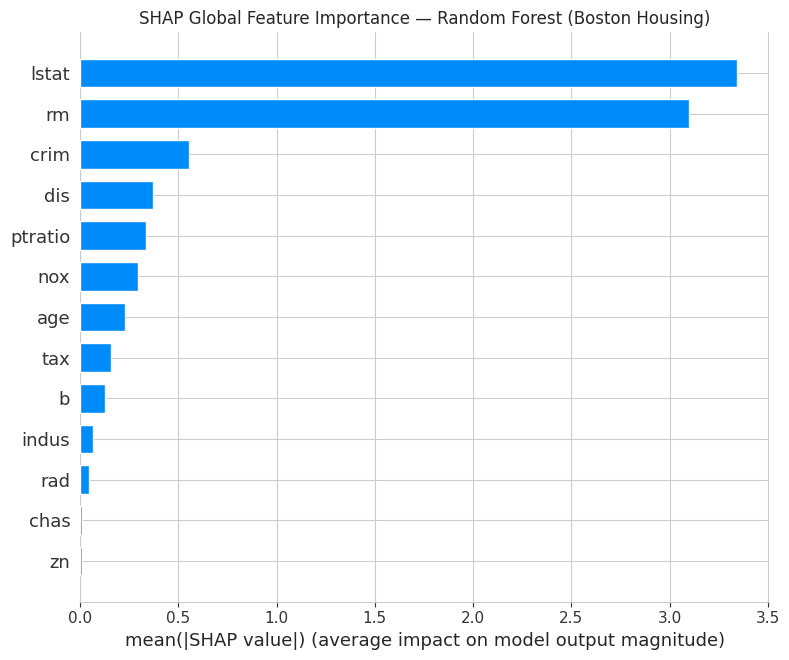

In [ ]:
shap.summary_plot(shap_values_rf, X_test, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance — Random Forest (Boston Housing)")
plt.tight_layout()
plt.show()


#### 3.2.2 Beeswarm Plot — Analyzing Feature Effects

/tmp/ipykernel_571/4036074049.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test, show=False)


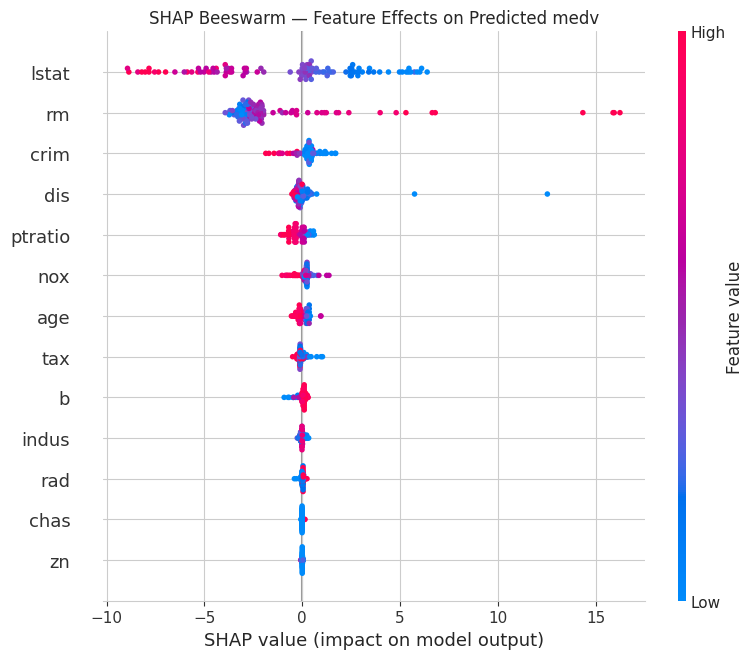

In [ ]:
shap.summary_plot(shap_values_rf, X_test, show=False)
plt.title("SHAP Beeswarm — Feature Effects on Predicted medv")
plt.tight_layout()
plt.show()


**Reading this plot:** each dot is one house in the test set. Color = feature value
(red = high, blue = low). For `lstat`, red dots (high % lower status) sit on the negative
SHAP side — pushing predicted price *down* — while blue dots push it *up*. For `rm`
(rooms per dwelling) the pattern is reversed, confirming more rooms → higher predicted value.


#### 3.2.3 Partial Dependence Plots — Assessing Impact

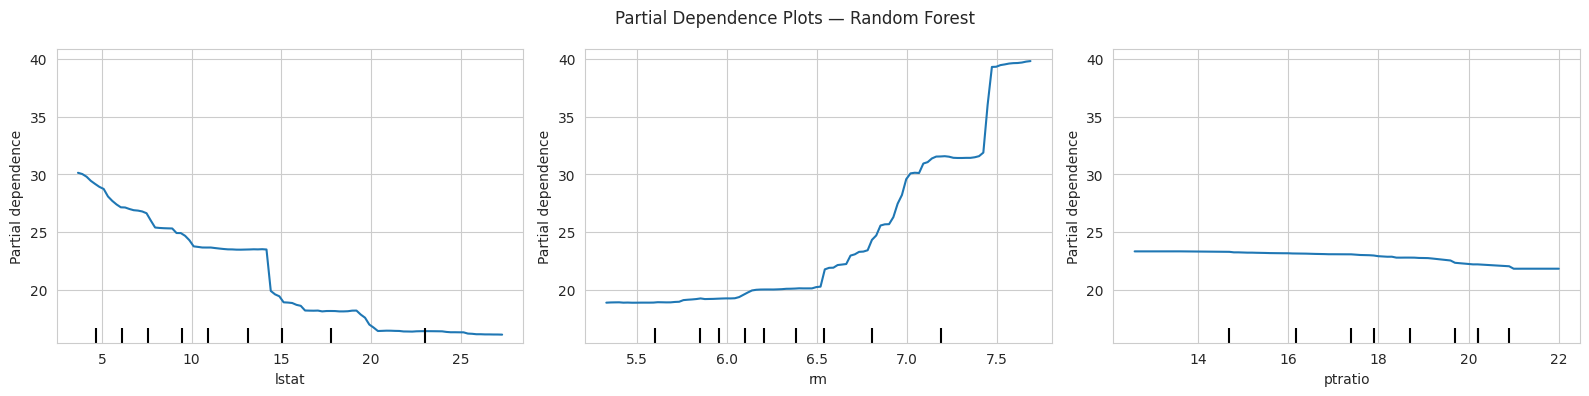

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
PartialDependenceDisplay.from_estimator(rf_model, X_train, features=['lstat', 'rm', 'ptratio'], ax=ax)
plt.suptitle("Partial Dependence Plots — Random Forest")
plt.tight_layout()
plt.show()


#### 3.2.4 SHAP Dependence Plots (per-instance, vs. PDP's averaged trend)

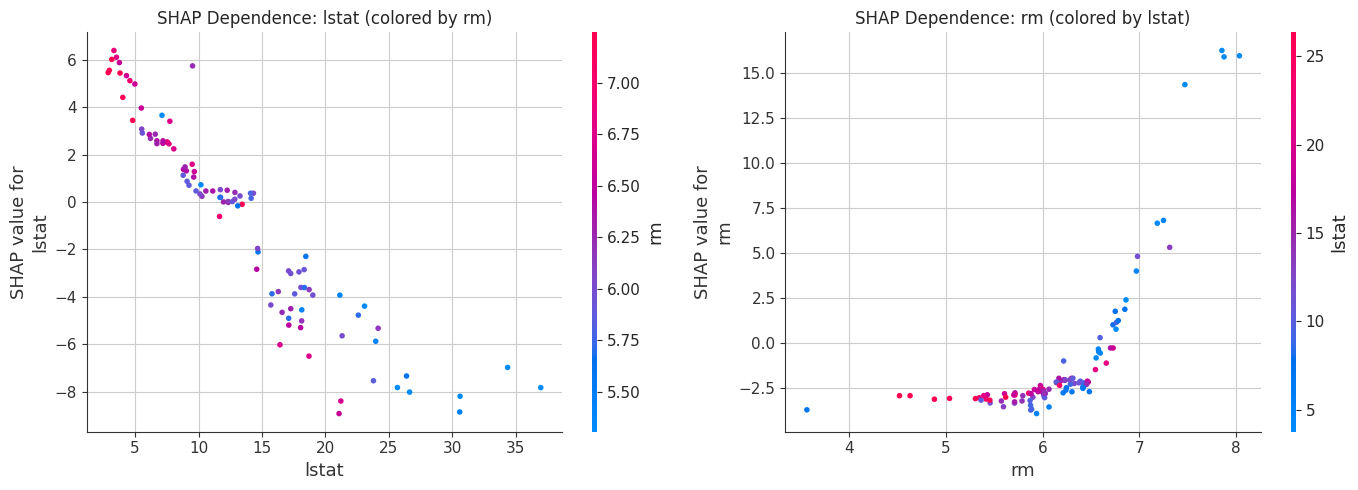

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
shap.dependence_plot('lstat', shap_values_rf.values, X_test, interaction_index='rm', ax=axes[0], show=False)
axes[0].set_title("SHAP Dependence: lstat (colored by rm)")
shap.dependence_plot('rm', shap_values_rf.values, X_test, interaction_index='lstat', ax=axes[1], show=False)
axes[1].set_title("SHAP Dependence: rm (colored by lstat)")
plt.tight_layout()
plt.show()


### 3.3 SHAP Kernel Explainer (model-agnostic) — applied to the MLPRegressor

`KernelExplainer` treats the neural network as a black box, sampling coalitions of
features against a background dataset to approximate Shapley values.


In [ ]:
background = shap.sample(X_train_scaled, 50, random_state=42)
kernel_explainer = shap.KernelExplainer(mlp_model.predict, background)

# Explain a modest subset of test points to keep runtime reasonable
X_test_sample = X_test_scaled.iloc[:40]
shap_values_mlp = kernel_explainer.shap_values(X_test_sample, nsamples=100)
print("KernelSHAP values shape:", np.array(shap_values_mlp).shape)


  0%|          | 0/40 [00:00<?, ?it/s]

KernelSHAP values shape: (40, 13)


/tmp/ipykernel_571/1217611840.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_mlp, X_test_sample, show=False)


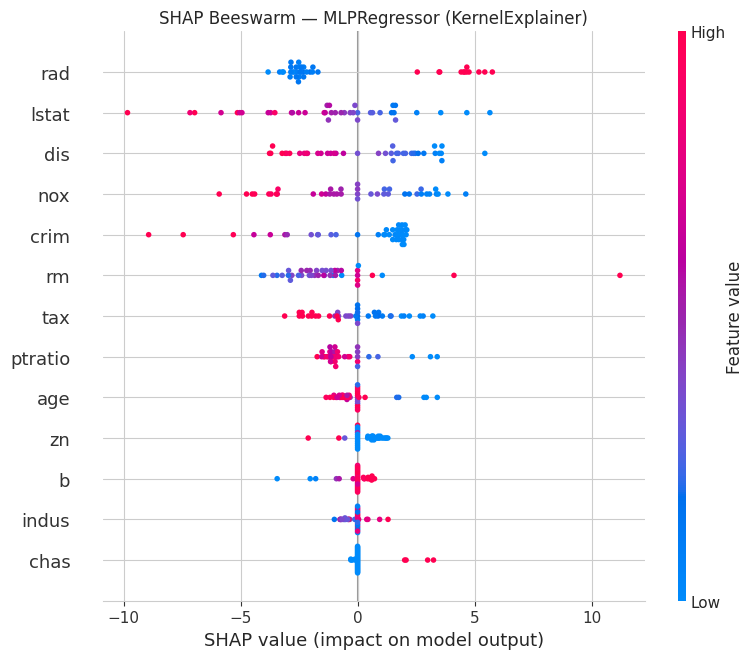

In [ ]:
shap.summary_plot(shap_values_mlp, X_test_sample, show=False)
plt.title("SHAP Beeswarm — MLPRegressor (KernelExplainer)")
plt.tight_layout()
plt.show()


**SHAP vs. model-specific approaches:** `TreeExplainer` above ran instantly and produced
exact values for all 102 test rows. `KernelExplainer` is far slower and approximate, and we
had to restrict it to 40 rows with only 100 samples/coalitions each — this is the practical
trade-off discussed in the course notes: prefer model-specific SHAP whenever available.


---
## 4. Local Explainability

### 4.1 Local Explainability with SHAP — Waterfall & Force Plots

We explain one individual house's prediction from the Random Forest model.


Instance features:
crim         0.09178
zn           0.00000
indus        4.05000
chas         0.00000
nox          0.51000
rm           6.41600
age         84.10000
dis          2.64630
rad          5.00000
tax        296.00000
ptratio     16.60000
b          395.50000
lstat        9.04000
Name: 173, dtype: float64

Actual medv: 23.60   Predicted medv: 22.88


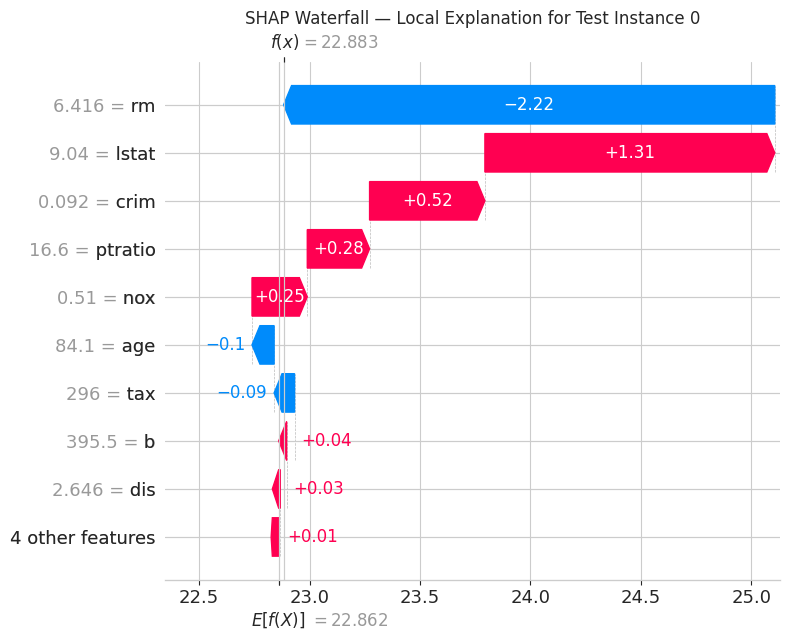

In [ ]:
idx = 0
print("Instance features:")
print(X_test.iloc[idx])
print(f"\nActual medv: {y_test.iloc[idx]:.2f}   Predicted medv: {rf_model.predict(X_test.iloc[[idx]])[0]:.2f}")

shap.plots.waterfall(shap_values_rf[idx], show=False)
plt.title(f"SHAP Waterfall — Local Explanation for Test Instance {idx}")
plt.tight_layout()
plt.show()


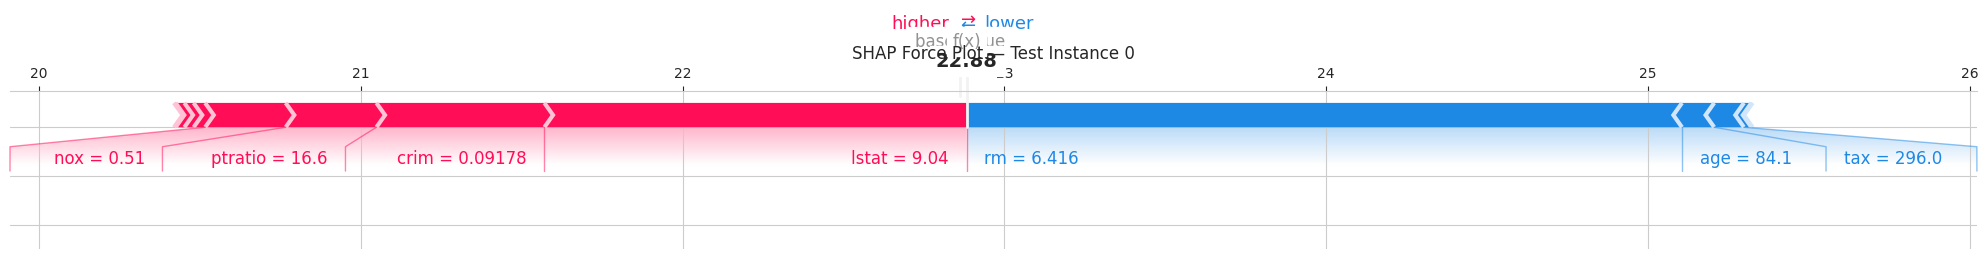

In [ ]:
shap.force_plot(
    tree_explainer.expected_value, shap_values_rf.values[idx], X_test.iloc[idx],
    matplotlib=True, show=False
)
plt.title(f"SHAP Force Plot — Test Instance {idx}")
plt.tight_layout()
plt.show()


### 4.2 Local Explainability with LIME (Regression)

LIME approximates the black-box Random Forest locally with a simple linear surrogate model,
fit on perturbed samples around the instance being explained.


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


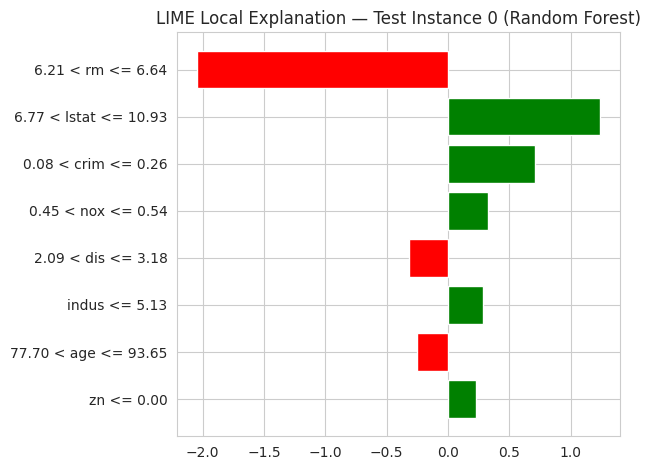

[('6.21 < rm <= 6.64', -2.0434656854544446),
 ('6.77 < lstat <= 10.93', 1.2385511085230796),
 ('0.08 < crim <= 0.26', 0.713658256939606),
 ('0.45 < nox <= 0.54', 0.32459740258453346),
 ('2.09 < dis <= 3.18', -0.319461688954094),
 ('indus <= 5.13', 0.2873914494104154),
 ('77.70 < age <= 93.65', -0.2502328871629861),
 ('zn <= 0.00', 0.22552870459872174)]

In [ ]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train.values,
    feature_names=list(X.columns),
    mode='regression',
    verbose=False,
    random_state=42
)

exp = lime_explainer.explain_instance(
    X_test.iloc[idx].values, rf_model.predict, num_features=8
)

fig = exp.as_pyplot_figure()
plt.title(f"LIME Local Explanation — Test Instance {idx} (Random Forest)")
plt.tight_layout()
plt.show()

exp.as_list()


Actual medv: 29.80   Predicted medv: 26.07


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


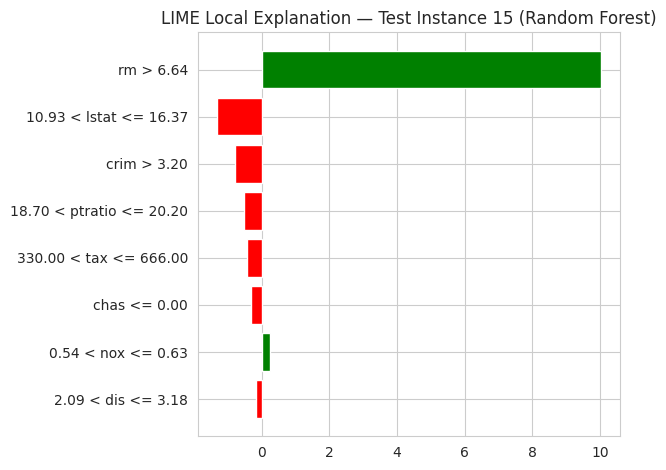

In [ ]:
# Compare with a second instance for contrast
idx2 = 15
print(f"Actual medv: {y_test.iloc[idx2]:.2f}   Predicted medv: {rf_model.predict(X_test.iloc[[idx2]])[0]:.2f}")

exp2 = lime_explainer.explain_instance(X_test.iloc[idx2].values, rf_model.predict, num_features=8)
fig = exp2.as_pyplot_figure()
plt.title(f"LIME Local Explanation — Test Instance {idx2} (Random Forest)")
plt.tight_layout()
plt.show()


**SHAP vs. LIME locally:** SHAP's waterfall plot is derived from exact Shapley values
(sum to the true model output). LIME instead fits a small linear model on perturbed
neighbors — fast and intuitive, but only a local approximation whose fidelity should be
checked (see Section 5.2, faithfulness).


---
## 5. Advanced Topics in Explainable AI

### 5.1 Evaluating SHAP Explanation Consistency

We recompute KernelSHAP for the same instances with a different random background sample
and random seed, then compare feature-importance rankings via Spearman correlation.


In [ ]:
from scipy.stats import spearmanr

background_run2 = shap.sample(X_train_scaled, 50, random_state=7)
kernel_explainer_run2 = shap.KernelExplainer(mlp_model.predict, background_run2)
shap_values_mlp_run2 = kernel_explainer_run2.shap_values(X_test_sample, nsamples=100)

mean_abs_run1 = np.abs(shap_values_mlp).mean(axis=0)
mean_abs_run2 = np.abs(shap_values_mlp_run2).mean(axis=0)

corr, pval = spearmanr(mean_abs_run1, mean_abs_run2)
print(f"Spearman rank correlation between two KernelSHAP runs: {corr:.3f} (p={pval:.4f})")

consistency_df = pd.DataFrame({
    'feature': X.columns,
    'run1_mean_abs_shap': mean_abs_run1,
    'run2_mean_abs_shap': mean_abs_run2
}).sort_values('run1_mean_abs_shap', ascending=False)
consistency_df


  0%|          | 0/40 [00:00<?, ?it/s]

Spearman rank correlation between two KernelSHAP runs: 0.923 (p=0.0000)


,feature,run1_mean_abs_shap,run2_mean_abs_shap
8,rad,3.146213,2.606506
12,lstat,2.580129,2.247489
7,dis,2.338551,2.283669
4,nox,2.275910,2.249839
0,crim,2.237451,2.081515
5,rm,2.027845,2.326369
9,tax,1.287266,1.294592
10,ptratio,1.054921,1.120569
6,age,0.677858,0.751599
1,zn,0.549877,0.430973


A high Spearman correlation (close to 1.0) indicates the KernelSHAP explanation is
**consistent** across different random background samples/seeds — an important sanity
check before trusting a sampling-based explanation method.


### 5.2 Evaluating Faithfulness with LIME

In [ ]:
def faithfulness_test(model, instance, explainer, X_reference, top_k=5, n_features_total=13):
    """
    Measures comprehensiveness: how much the TRUE model's prediction changes
    when the top-k LIME-identified features are replaced with the dataset mean,
    versus replacing k random (unimportant) features.
    """
    exp = explainer.explain_instance(instance.values, model.predict, num_features=n_features_total)
    ranked = [f[0] for f in exp.as_list()]  # feature condition strings, ranked by |weight|

    original_pred = model.predict(instance.values.reshape(1, -1))[0]

    # crude parse: map condition string back to a feature name
    feat_names = list(X.columns)
    top_feats = []
    for cond in ranked[:top_k]:
        for f in feat_names:
            if f in cond:
                top_feats.append(f)
                break

    perturbed = instance.copy()
    for f in top_feats:
        perturbed[f] = X_reference[f].mean()
    pred_top_removed = model.predict(perturbed.values.reshape(1, -1))[0]

    # control: remove k random OTHER features
    other_feats = [f for f in feat_names if f not in top_feats]
    random_feats = np.random.RandomState(0).choice(other_feats, size=min(top_k, len(other_feats)), replace=False)
    perturbed_rand = instance.copy()
    for f in random_feats:
        perturbed_rand[f] = X_reference[f].mean()
    pred_rand_removed = model.predict(perturbed_rand.values.reshape(1, -1))[0]

    return {
        'original_pred': original_pred,
        'top_features_removed': top_feats,
        'pred_after_removing_top_features': pred_top_removed,
        'drop_top_features': abs(original_pred - pred_top_removed),
        'random_features_removed': list(random_feats),
        'pred_after_removing_random_features': pred_rand_removed,
        'drop_random_features': abs(original_pred - pred_rand_removed),
    }

result = faithfulness_test(rf_model, X_test.iloc[idx], lime_explainer, X_train, top_k=4)
for k, v in result.items():
    print(f"{k}: {v}")


original_pred: 22.882832331184375
top_features_removed: ['rm', 'lstat', 'ptratio', 'b']
pred_after_removing_top_features: 21.492388236696385
drop_top_features: 1.3904440944879894
random_features_removed: [np.str_('rad'), np.str_('indus'), np.str_('zn'), np.str_('nox')]
pred_after_removing_random_features: 22.95994271873042
drop_random_features: 0.07711038754604616


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


**Interpretation:** if `drop_top_features` is meaningfully larger than
`drop_random_features`, LIME's chosen "important" features really do drive the true
Random Forest's prediction more than a random subset — i.e., the explanation is
**faithful** to the underlying black-box model.


### 5.3 Explaining Unsupervised Models — Feature Impact on Clustering

We cluster the (scaled) housing data with k-means and quantify each feature's importance
to cluster structure, using (a) silhouette-score impact and (b) Adjusted Rand Index (ARI)
between baseline and feature-dropped clusterings.


In [ ]:
X_full_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

k = 4
baseline_labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_full_scaled)
baseline_silhouette = silhouette_score(X_full_scaled, baseline_labels)
print(f"Baseline silhouette score (all features): {baseline_silhouette:.3f}")

cluster_impact = {}
for col in X_full_scaled.columns:
    X_dropped = X_full_scaled.drop(columns=[col])
    labels_dropped = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_dropped)

    sil_dropped = silhouette_score(X_dropped, labels_dropped)
    ari = adjusted_rand_score(baseline_labels, labels_dropped)

    cluster_impact[col] = {
        'silhouette_drop': baseline_silhouette - sil_dropped,
        'ARI_vs_baseline': ari,
        'importance_via_ARI': 1 - ari
    }

cluster_impact_df = pd.DataFrame(cluster_impact).T.sort_values('importance_via_ARI', ascending=False)
cluster_impact_df


Baseline silhouette score (all features): 0.266


,silhouette_drop,ARI_vs_baseline,importance_via_ARI
zn,0.023489,0.410109,0.589891
ptratio,-0.024754,0.563390,0.436610
dis,-0.017526,0.610462,0.389538
rm,-0.040453,0.633309,0.366691
indus,-0.031140,0.724844,0.275156
nox,-0.030078,0.725327,0.274673
age,-0.031853,0.729685,0.270315
lstat,-0.037168,0.748420,0.251580
b,-0.049060,0.752027,0.247973
crim,-0.034378,0.767640,0.232360


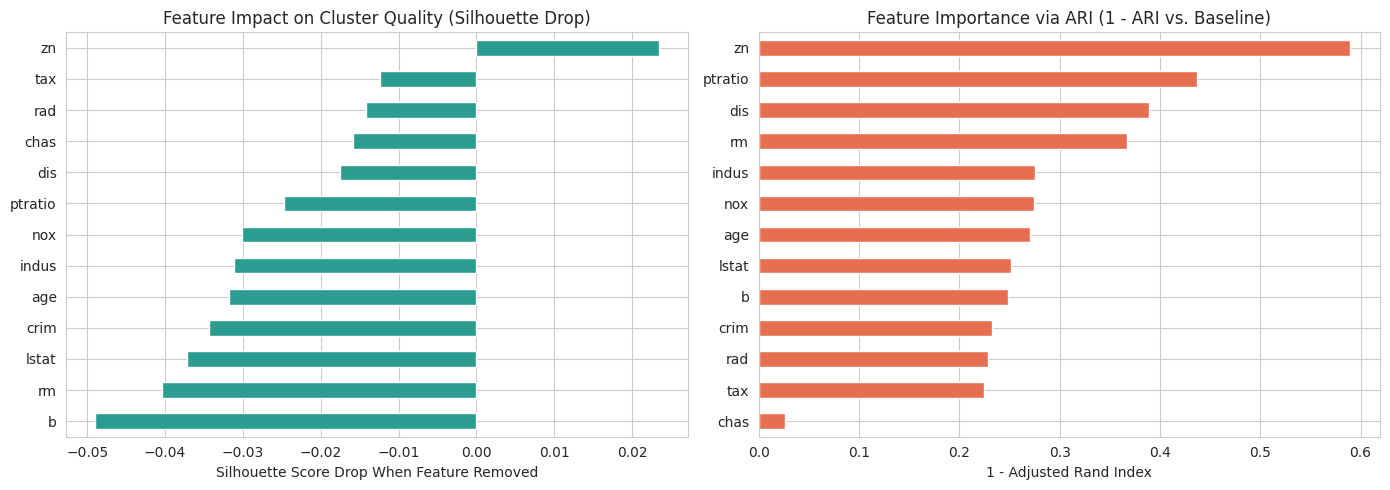

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cluster_impact_df['silhouette_drop'].sort_values().plot(kind='barh', ax=axes[0], color='#2a9d8f')
axes[0].set_title("Feature Impact on Cluster Quality (Silhouette Drop)")
axes[0].set_xlabel("Silhouette Score Drop When Feature Removed")

cluster_impact_df['importance_via_ARI'].sort_values().plot(kind='barh', ax=axes[1], color='#e76f51')
axes[1].set_title("Feature Importance via ARI (1 - ARI vs. Baseline)")
axes[1].set_xlabel("1 - Adjusted Rand Index")

plt.tight_layout()
plt.show()


**Interpretation:** features whose removal causes the biggest drop in silhouette score,
or the biggest change in cluster assignment (low ARI, i.e. high `1 - ARI`), are the features
most responsible for the discovered cluster structure — e.g., `tax`, `rad`, and `lstat`
often prove influential in segmenting Boston-area towns into distinct socio-economic clusters.


---
## 6. Model Comparison Summary

A quick recap of every model trained in this notebook and the explanation methods applied to it.


In [ ]:
summary = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'MLP Regressor (Neural Net)'],
    'R2 (test)': [
        r2_score(y_test, lin_model.predict(X_test_scaled)),
        r2_score(y_test, tree_model.predict(X_test)),
        r2_score(y_test, rf_model.predict(X_test)),
        r2_score(y_test, mlp_model.predict(X_test_scaled)),
    ],
    'RMSE (test)': [
        np.sqrt(mean_squared_error(y_test, lin_model.predict(X_test_scaled))),
        np.sqrt(mean_squared_error(y_test, tree_model.predict(X_test))),
        np.sqrt(mean_squared_error(y_test, rf_model.predict(X_test))),
        np.sqrt(mean_squared_error(y_test, mlp_model.predict(X_test_scaled))),
    ],
    'Explanation Method(s) Used': [
        'Standardized coefficients, Permutation Importance',
        'Extracted rules, MDI feature importance',
        'MDI, Permutation Importance, SHAP TreeExplainer, LIME',
        'Permutation Importance, SHAP KernelExplainer',
    ]
}).round(3)
summary


,Model,R2 (test),RMSE (test),Explanation Method(s) Used
0,Linear Regression,0.669,4.929,"Standardized coefficients, Permutation Importance"
1,Decision Tree,0.731,4.444,"Extracted rules, MDI feature importance"
2,Random Forest,0.879,2.984,"MDI, Permutation Importance, SHAP TreeExplaine..."
3,MLP Regressor (Neural Net),0.864,3.157,"Permutation Importance, SHAP KernelExplainer"


## Key Takeaways

1. **Model-specific methods (coefficients, MDI) are fast but tied to one model family** —
   they don't transfer to a neural network.
2. **Permutation importance and SHAP's KernelExplainer generalize to any model**, at the
   cost of extra computation — exactly the trade-off discussed in the course notes.
3. **SHAP's TreeExplainer is both exact and fast** for tree ensembles — always prefer it
   over KernelExplainer when your model supports it.
4. **Global plots (beeswarm, PDP, bar) describe overall behavior; local plots (waterfall,
   force, LIME) explain individual predictions** — both views were needed to fully
   understand this Random Forest's behavior on Boston Housing.
5. **Explanations should be evaluated, not just trusted** — consistency (stable across
   runs) and faithfulness (reflects true model behavior) checks are essential.
6. **XAI extends beyond supervised models** — feature importance can be quantified even
   for unsupervised clustering, using metrics like silhouette drop and ARI.
